In [ ]:
#测试环境
import torch
print(torch.__version__)
print(torch.cuda.is_available())  # 应该输出 True

# 输入数据集链接并下载解压
!wget https://download.pytorch.org/tutorial/hymenoptera_data.zip
!unzip -o hymenoptera_data.zip

# 验证下载成功
import os
print(os.listdir('hymenoptera_data'))

2.11.0+cpu
False
--2026-06-05 04:19:38--  https://download.pytorch.org/tutorial/hymenoptera_data.zip
Resolving download.pytorch.org (download.pytorch.org)... 3.173.161.80, 3.173.161.98, 3.173.161.118, ...
Connecting to download.pytorch.org (download.pytorch.org)|3.173.161.80|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 47286322 (45M) [application/zip]
Saving to: ‘hymenoptera_data.zip’

hymenoptera_data.zi 100%[===================>]  45.10M  27.5MB/s    in 1.6s    

2026-06-05 04:19:41 (27.5 MB/s) - ‘hymenoptera_data.zip’ saved [47286322/47286322]

Archive:  hymenoptera_data.zip
   creating: hymenoptera_data/
   creating: hymenoptera_data/train/
   creating: hymenoptera_data/train/ants/
  inflating: hymenoptera_data/train/ants/0013035.jpg  
  inflating: hymenoptera_data/train/ants/1030023514_aad5c608f9.jpg  
  inflating: hymenoptera_data/train/ants/1095476100_3906d8afde.jpg  
  inflating: hymenoptera_data/train/ants/1099452230_d1949d3250.jpg  
  inflating: h

In [ ]:
#使用dataset类工具
from torch.utils.data import Dataset
#查看官方文档
help(Dataset)

Help on class Dataset in module torch.utils.data.dataset:

class Dataset(typing.Generic)
 |  An abstract class representing a :class:`Dataset`.
 |
 |  All datasets that represent a map from keys to data samples should subclass
 |  it. All subclasses should overwrite :meth:`__getitem__`, supporting fetching a
 |  data sample for a given key. Subclasses could also optionally overwrite
 |  :meth:`__len__`, which is expected to return the size of the dataset by many
 |  :class:`~torch.utils.data.Sampler` implementations and the default options
 |  of :class:`~torch.utils.data.DataLoader`. Subclasses could also
 |  optionally implement :meth:`__getitems__`, for speedup batched samples
 |  loading. This method accepts list of indices of samples of batch and returns
 |  list of samples.
 |
 |  .. note::
 |    :class:`~torch.utils.data.DataLoader` by default constructs an index
 |    sampler that yields integral indices.  To make it work with a map-style
 |    dataset with non-integral indices

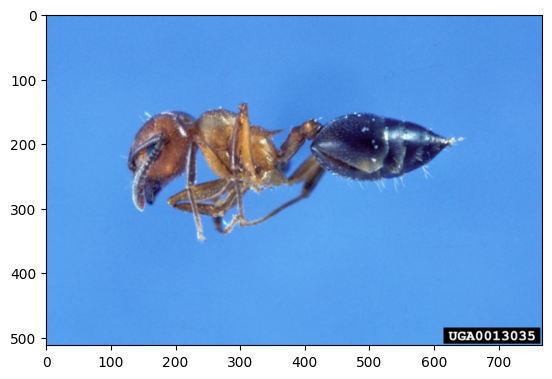

In [ ]:
from torch.utils.data import Dataset
from PIL import Image
import matplotlib.pyplot as plt

# 打开图片
img = Image.open('hymenoptera_data/train/ants/0013035.jpg')
plt.imshow(img)# 显示图片，vscode用img.show()也行
plt.show()

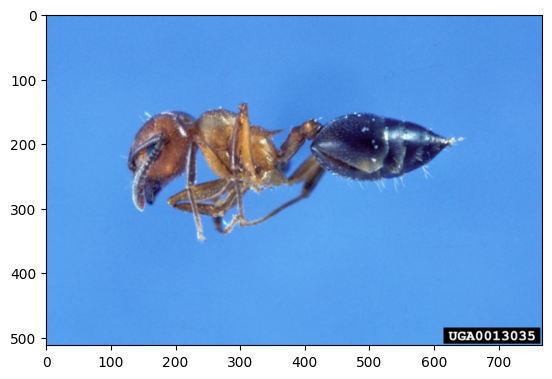

['470127037_513711fd21.jpg', '245647475_9523dfd13e.jpg', '167890289_dd5ba923f3.jpg', 'imageNotFound.gif', 'formica.jpeg']
共有124张图片


In [ ]:
from PIL import Image
import os
import matplotlib.pyplot as plt

# 1. 打开单张图片
img_path = "hymenoptera_data/train/ants/0013035.jpg"# 单张图片的路径
img = Image.open(img_path)# 打开该路径图片
plt.imshow(img)   # 显示图片
plt.show()

# 2. 列出蚂蚁文件夹所有图片名
dir_path = "hymenoptera_data/train/ants" #完整ants文件夹路径
img_path_list = os.listdir(dir_path) #列出文件夹里的所有文件名称
print(img_path_list[:5])  # 打印前5个看看
print(f"共有{len(img_path_list)}张图片")


In [ ]:
from torch.utils.data import Dataset # 从 PyTorch 的数据工具包中导入基类 Dataset
from PIL import Image # 从 PIL 库导入 Image 用于后续读取图片
import os # 导入 os 库用于系统路径和文件操作

# 定义一个叫 MyData 的类，继承自 PyTorch 的 Dataset 基础类
class MyData(Dataset):
    def __init__(self, root_dir, label_dir):
        # 构造函数：初始化类的时候自动运行，用来接收外部传入的路径参数
        # self将外部传入的参数保存为类内部的专属属性（全局变量）
        # 这样在下方的 __getitem__ 等方法里才能随时跨函数使用这些路径
        self.root_dir = root_dir      # 保存根目录路径，例如 "dataset/train"
        self.label_dir = label_dir    # 保存标签目录路径，例如 "ants"

        # 使用 os.path.join 自动拼接两目录，得到完整文件夹路径
        # Windows会自动拼成 "dataset\\train\\ants" (双反杠是Windows特色，函数会处理)
        self.path = os.path.join(self.root_dir, self.label_dir)

        # 获取该路径下的所有图片文件名，返回一个文件名列表
        # 此时self.img_path 里存的：['0013035.jpg', '5650366_e22b7e1001.jpg', ...]
        self.img_path = os.listdir(self.path)

    def __getitem__(self, index):
        img_name = self.img_path[index]
        img_item_path = os.path.join(self.root_dir, self.label_dir, img_name)
        img = Image.open(img_item_path)
        return img

    def __len__(self):
        return len(self.img_path)

In [ ]:
# 1. 准备好要传入构造函数的真实文件夹路径
root_dir = "hymenoptera_data/train"
label_dir = "ants"

# 2. 实例化：创造出一个名叫 ants_dataset 的数据集对象
# 在运行这一行时，系统会自动去执行上面类定义中的 __init__ 构造函数
ants_dataset = MyData(root_dir, label_dir)

# 3. 打印对象的内部属性，验证路径拼接和文件列表读取是否成功
print("拼接出的完整路径是:", ants_dataset.path)
print("获取到的前 5 张图片文件名:", ants_dataset.img_path[:5])

拼接出的完整路径是: hymenoptera_data/train/ants
获取到的前 5 张图片文件名: ['470127037_513711fd21.jpg', '245647475_9523dfd13e.jpg', '167890289_dd5ba923f3.jpg', 'imageNotFound.gif', 'formica.jpeg']


In [ ]:
import os
from PIL import Image
from torch.utils.data import Dataset

# 定义一个叫 MyData 的类，继承自 PyTorch 的 Dataset 基础类
class MyData(Dataset):

    # 1. 构造函数：初始化类（扫描文件，建立目录索引，不直接读图）
    def __init__(self, root_dir, label_dir):
        self.root_dir = root_dir      # 保存根目录路径，例如 "hymenoptera_data/train"
        self.label_dir = label_dir    # 保存标签目录路径，例如 "ants"
        self.path = os.path.join(self.root_dir, self.label_dir) # 拼接完整文件夹路径
        self.img_path = os.listdir(self.path) # 读取该路径下的所有图片文件名

    # 2. 核心取值函数：通过索引 index 获取单张图片及对应的分类标签
    def __getitem__(self, index):
        # 依据 index 索引，从文件名列表中拿到对应的图片文件名
        # 例如 index=0 时，img_name = '0013035.jpg'
        img_name = self.img_path[index]

        # 拼接出该张图片的完整物理存储路径
        img_item_path = os.path.join(self.root_dir, self.label_dir, img_name)

        # 此时才真正去磁盘读取图片数据（延迟加载）
        img = Image.open(img_item_path)

        # 获取该图片的类别标签（这里直接使用文件夹名字作为类别）
        label = self.label_dir

        # 返回图片数据和对应答案（标签），形如 (img, label) 的元组 (Tuple)
        return img, label

    # 3. 长度函数：获取该数据集的总样本数
    def __len__(self):
        # self.img_path 是文件名列表，其长度就是当前数据集包含的图片总张数
        return len(self.img_path)

In [ ]:
# Re-execute the correct MyData class definition
# This ensures the __getitem__ method returns both image and label
import os
from PIL import Image
from torch.utils.data import Dataset

class MyData(Dataset):
    def __init__(self, root_dir, label_dir):
        self.root_dir = root_dir
        self.label_dir = label_dir
        self.path = os.path.join(self.root_dir, self.label_dir)
        self.img_path = os.listdir(self.path)

    def __getitem__(self, index):
        img_name = self.img_path[index]
        img_item_path = os.path.join(self.root_dir, self.label_dir, img_name)
        img = Image.open(img_item_path)
        label = self.label_dir
        return img, label

    def __len__(self):
        return len(self.img_path)

Type of image: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Label: bees


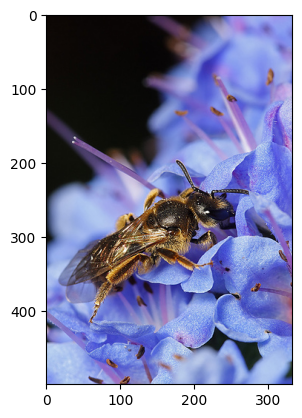

In [ ]:
# 1. 准备要传入数据集构造函数的路径参数，root_dir 是存放训练集的总根目录
root_dir = "hymenoptera_data/train"
# ants_label_dir 是蚂蚁文件夹的名字，同时也是蚂蚁的分类标签 (Label)
ants_label_dir = "ants"
# bees_label_dir 是蜜蜂文件夹的名字，同时也是蜜蜂的分类标签 (Label)
bees_label_dir = "bees"

# 2. 实例化阶段 ── 触发并测试 __init__ 构造函数
# 创建蚂蚁数据集实例：此时系统会自动在内存中建立蚂蚁图片的文件名列表（图书目录）
ants_dataset = MyData(root_dir, ants_label_dir)
# 创建蜜蜂数据集实例：同上，建立蜜蜂图片的文件名列表（图书目录）
bees_dataset = MyData(root_dir, bees_label_dir)
train_dataset = ants_dataset + bees_dataset

# 3. 索引取值阶段 ── 触发并测试 __getitem__ 魔法方法
# 通过方括号 [99] 传入索引，系统自动运行类内的 __getitem__(self, 99) 方法。
# 它会去磁盘上读取第 100 张蜜蜂图片，并将图片和对应的标签以元组形式返回。
# 这里使用 img 和 label 两个变量进行“元组解包”接收。
img, label = bees_dataset[99]

# 4. 打印验证：输出图片的类型，确认是否是 PIL 库成功读取的图片对象
print(f"Type of image: {type(img)}")
# 预期输出: Type of image: <class 'PIL.JpegImagePlugin.JpegImageFile'>

# 5. 打印验证：输出取出的标签，确认是否正确对应为 'bees'
print(f"Label: {label}")
# 预期输出: Label: bees

# 6. 数据可视化验证：导入 matplotlib 绘图工具箱，起个别名叫 plt
import matplotlib.pyplot as plt

# 将读取出来的蜜蜂图片数据 (img) 送入 matplotlib 画板
plt.imshow(img)

# 将画板渲染并正式展示在屏幕上，看到这只小蜜蜂
plt.show()

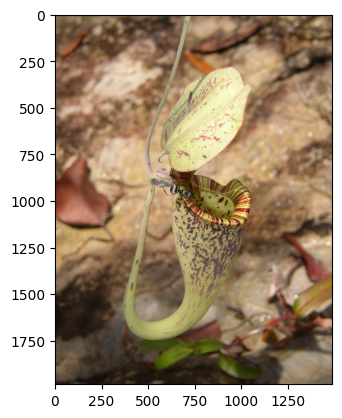

124
121
245


In [ ]:
# 1. 准备要传入数据集构造函数的路径参数，root_dir 是存放训练集的总根目录
root_dir = "hymenoptera_data/train"
# ants_label_dir 是蚂蚁文件夹的名字，同时也是蚂蚁的分类标签 (Label)
ants_label_dir = "ants"
# bees_label_dir 是蜜蜂文件夹的名字，同时也是蜜蜂的分类标签 (Label)
bees_label_dir = "bees"

# 2. 实例化阶段 ── 触发并测试 __init__ 构造函数
# 创建蚂蚁数据集实例：此时系统会自动在内存中建立蚂蚁图片的文件名列表（图书目录）
ants_dataset = MyData(root_dir, ants_label_dir)
# 创建蜜蜂数据集实例：同上，建立蜜蜂图片的文件名列表（图书目录）
bees_dataset = MyData(root_dir, bees_label_dir)
train_dataset = ants_dataset + bees_dataset
img,label = train_dataset[123]

# 6. 数据可视化验证：导入 matplotlib 绘图工具箱，起个别名叫 plt
import matplotlib.pyplot as plt

# 将读取出来的蜜蜂图片数据 (img) 送入 matplotlib 画板
plt.imshow(img)

# 将画板渲染并正式展示在屏幕上，看到这只小蜜蜂
plt.show()
# 将画板渲染并正式展示

print(len(ants_dataset))
print(len(bees_dataset))
print(len(train_dataset))

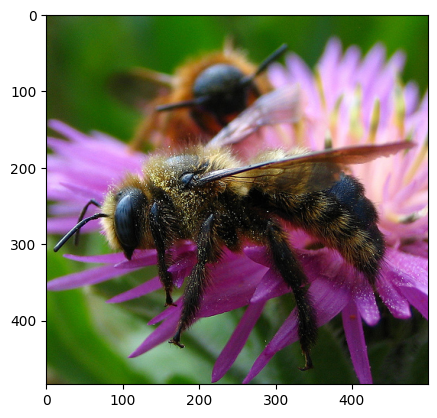

124
121
245


In [ ]:
# 1. 准备路径参数
root_dir = "hymenoptera_data/train"
ants_label_dir = "ants"
bees_label_dir = "bees"

# 2. 实例化两个独立的数据集
# 蚂蚁数据集（包含 124 张图片，索引为 0 ~ 123）
ants_dataset = MyData(root_dir, ants_label_dir)
# 蜜蜂数据集（包含 121 张图片，索引为 0 ~ 120）
bees_dataset = MyData(root_dir, bees_label_dir)

# 操作 1：使用加号拼接数据集 (Dataset Concatenation)
# PyTorch 允许直接用 + 将两个 Dataset 对象相加。
# 这在底层会调用 PyTorch 的 ConcatDataset 类，将它们拼接为一个拥有 245 张图片的大数据集。
train_dataset = ants_dataset + bees_dataset

# 操作 2：从拼接后的数据集中读取数据 (Indexing)
# 尝试读取索引为 124（第 125 张）的图片。
# 根据底层映射逻辑，前 124 张（0~123）是蚂蚁，第 125 张（索引 124）正好是蜜蜂的第一张图。
# 此时，PyTorch 会在底层自动帮我们去读取并返回蜜蜂的第一张图片数据。
img, label = train_dataset[244]


# 3. 数据可视化验证（会画出一只蜜蜂）

import matplotlib.pyplot as plt
plt.imshow(img)
plt.show()


# 4. 打印长度进行验证

print(len(ants_dataset))     # 输出: 124 (蚂蚁数量)
print(len(bees_dataset))     # 输出: 121 (蜜蜂数量)
print(len(train_dataset))    # 输出: 245 (两者相加：124 + 121 = 245)